<a id="top"></a>
<div style="background:#EFF6FF;border-left:6px solid #2563EB;padding:26px;font-family:Arial,sans-serif;">
<p style="color:#17324D;font-size:13px;font-weight:700;letter-spacing:2px;">PORTFOLIO DATA · SEGMENTATION CLIENTÈLE</p>
<h1 style="color:#2563EB;font-weight:700;margin:12px 0;">Comprendre les clients pour construire des hypothèses marketing</h1>
<p style="color:#111827;font-size:17px;">Une analyse complète : qualité des données, exploration, ACP, clustering, évaluation et profilage.</p>
</div>

**Projet académique collectif · ENSEA Abidjan · Data Mining · AS3, juillet 2025**

KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc · SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël  
Supervision : **M. LALY**.

<table style="width:100%;border-collapse:collapse;font-family:Arial,sans-serif;color:#111827;background:#F3F4F6;">
<thead><tr style="background:#D1D5DB;"><th style="padding:14px;font-weight:700;">Clients analysés</th><th style="padding:14px;font-weight:700;">Segments étudiés</th><th style="padding:14px;font-weight:700;">Variance conservée</th><th style="padding:14px;font-weight:700;">Silhouette</th></tr></thead>
<tbody><tr><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#1D4ED8;">2 212</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#0F766E;">4</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#B45309;">61,0 %</td><td style="background:#F3F4F6;padding:16px;text-align:center;font-size:24px;font-weight:700;color:#6D28D9;">0,304</td></tr></tbody>
</table>

**Question étudiée.** Comment regrouper des clients à partir de leurs caractéristiques et de leurs achats, puis décrire les comportements observés dans chaque groupe ? Les propositions commerciales finales sont des **hypothèses à tester** ; ce jeu de données ne mesure pas les effets causaux d’une action marketing.

**Parcours de lecture**

1. [Environnement et charte visuelle](#1)
2. [Données et premier aperçu](#2)
3. [Qualité, exploration et création de variables](#3)
4. [Prétraitement et choix de représentation](#4)
5. [ACP et projection 3D interactive](#5)
6. [Construction des segments et vue 3D interactive](#6)
7. [Évaluation et comportements d’achat](#7)
8. [Profils des clients](#8)
9. [Enseignements, hypothèses et limites](#9)
10. [Sources et équipe](#10)

**Graphiques 3D :** rotation et zoom dans VS Code/Jupyter ; exports HTML autonomes dans `reports/figures_interactives/`. Sur GitHub, les aperçus du notebook sont statiques.

<a id="1"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">01 · Environnement et charte visuelle</h2>

Les couleurs identifient les mêmes clusters dans toutes les figures. Les tableaux utilisent un fond gris clair et un texte noir.

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
import seaborn as sns
import missingno as msno

# Prétraitement
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA

# Clustering et évaluation
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

warnings.simplefilter("ignore")

# Graine fixée pour la reproductibilité
np.random.seed(42)

# Dossier des figures reprises dans le README
IMG_DIR = "images"
os.makedirs(IMG_DIR, exist_ok=True)
 


# Présentation : palette contrastée sur fond blanc.
import io
import json
from pathlib import Path
import matplotlib.ticker as mticker
import plotly.graph_objects as go
from IPython.display import display

BLEU = "#2563EB"
ENCRE = "#17324D"
pal = ["#1D4ED8", "#0F766E", "#B45309", "#6D28D9"]
cmap = ListedColormap(pal)
sns.set_theme(style="whitegrid", palette=pal, rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "text.color": "#111827", "axes.labelcolor": "#111827",
    "xtick.color": "#111827", "ytick.color": "#111827",
    "axes.titlecolor": ENCRE, "axes.titleweight": "bold",
    "axes.titlesize": 15, "axes.labelsize": 11,
    "grid.color": "#E5E7EB", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "figure.figsize": (10, 6), "figure.dpi": 110,
})
Path("reports/figures_interactives").mkdir(parents=True, exist_ok=True)

def tableau(frame, precision=2):
    """Tableau lisible, également conservé dans les sorties du notebook."""
    return (frame.style.format(precision=precision, na_rep="—")
            .set_properties(**{"background-color": "#F3F4F6", "color": "#000000",
                               "padding": "9px 12px", "border-bottom": "1px solid #D1D5DB"})
            .set_table_styles([
                {"selector": "table", "props": [("font-family", "Arial, sans-serif"), ("border-collapse", "collapse")]},
                {"selector": "th", "props": [("background-color", "#D1D5DB"), ("color", "#000000"),
                                                ("font-weight", "700"), ("padding", "9px 12px")]},
                {"selector": "tbody tr:nth-child(even) td", "props": [("background-color", "#E5E7EB")]},
            ]))

def sauvegarder(nom_fichier):
    """Enregistre la figure courante pour le README et la présentation."""
    plt.savefig(Path(IMG_DIR) / nom_fichier, dpi=160, bbox_inches="tight", facecolor="white")

def note_figure(fig, texte):
    fig.text(0.01, 0.01, texte, fontsize=9, color="#334155", va="bottom")

def graphique_3d(frame, titre, groupes=False):
    """Les axes et les clients sont identiques à la projection statique."""
    figure = go.Figure()
    for groupe in (range(4) if groupes else [None]):
        masque = frame["Clusters"].eq(groupe).to_numpy() if groupes else np.ones(len(frame), dtype=bool)
        subset = frame.loc[masque]
        informations = data.loc[masque, ["Income", "Spent", "Age"]].round(1).to_numpy().tolist()
        figure.add_trace(go.Scatter3d(
            x=subset["axe1"].tolist(), y=subset["axe2"].tolist(), z=subset["axe3"].tolist(),
            customdata=informations, mode="markers",
            name=f"Cluster {groupe} · {len(subset)} clients" if groupes else "Clients",
            marker=dict(size=3.5, color=pal[groupe] if groupes else pal[0], opacity=0.75),
            hovertemplate="Axe 1 : %{x:.2f}<br>Axe 2 : %{y:.2f}<br>Axe 3 : %{z:.2f}"
                          "<br>Revenu : %{customdata[0]:,.0f}<br>Dépenses : %{customdata[1]:,.0f}"
                          "<br>Âge en 2014 : %{customdata[2]:.0f}<extra>%{fullData.name}</extra>",
        ))
    figure.update_layout(
        title=dict(text=titre, font=dict(size=21, color=ENCRE)),
        template="plotly_white", height=670, paper_bgcolor="white", font=dict(color="#111827", size=12),
        margin=dict(l=10, r=200 if groupes else 10, t=75, b=75),
        showlegend=groupes, legend=dict(orientation="v", y=0.95, x=1.02, xanchor="left", font=dict(size=11)),
        scene=dict(xaxis_title="Axe 1", yaxis_title="Axe 2", zaxis_title="Axe 3",
                   bgcolor="white", aspectmode="data", dragmode="orbit",
                   camera=dict(eye=dict(x=1.5, y=1.5, z=1.1))),
        annotations=[dict(x=0, y=-0.09, xref="paper", yref="paper", showarrow=False,
                          text=f"Vue 3D : {cumulative_variance_full[2]:.1%} de la variance · Modèle : 4 axes ({cumulative_variance_full[3]:.1%})",
                          font=dict(size=11, color="#334155"))],
    )
    return figure

def afficher_3d(figure, statique, nom_html):
    """Même sortie : Plotly interactif dans l'IDE, PNG de secours sur GitHub."""
    image_buffer = io.BytesIO()
    statique.savefig(image_buffer, format="png", dpi=135, bbox_inches="tight", facecolor="white")
    plt.close(statique)
    config = {"displaylogo": False, "scrollZoom": True, "responsive": True}
    plotly_bundle = json.loads(figure.to_json())
    plotly_bundle["config"] = config
    display({"application/vnd.plotly.v1+json": plotly_bundle,
             "image/png": __import__("base64").b64encode(image_buffer.getvalue()).decode("ascii"),
             "text/plain": "Graphique 3D interactif ; aperçu statique disponible sur GitHub."}, raw=True)
    contenu = figure.to_html(full_html=False, include_plotlyjs=True, config=config)
    page = """<!doctype html><html lang="fr"><head><meta charset="utf-8">
    <meta name="viewport" content="width=device-width, initial-scale=1"><title>Segmentation · Vue 3D</title>
    <style>body{margin:0;padding:24px;background:#F3F4F6;color:#111827;font:15px Arial,sans-serif}
    main{max-width:1200px;margin:auto;background:white;padding:24px;border-radius:12px}
    h1{color:#2563EB;font-size:26px} .guide{background:#EFF6FF;border-left:4px solid #2563EB;padding:14px;line-height:1.6}
    footer{border-top:1px solid #D1D5DB;margin-top:18px;padding-top:16px;line-height:1.6;font-size:13px}</style></head><body><main>
    <h1>Segmentation de la clientèle · Exploration 3D</h1>
    <div class="guide"><strong>Explorer :</strong> faites glisser pour tourner, utilisez la molette pour zoomer et survolez un point pour lire son profil.
    Cliquez sur la légende pour masquer un groupe ; double-cliquez pour l'isoler. Les montants sont exprimés dans les unités du jeu de données.</div>"""
    page += contenu + """<footer><strong>Abdoulaye KONE</strong> · Contribution au projet collectif ENSEA, Data Mining 2025.<br>
    Équipe : KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc · SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël.<br>
    Supervision : M. LALY. Données : Customer Personality Analysis, Akash Patel, Kaggle.</footer></main></body></html>"""
    destination = Path("reports/figures_interactives") / nom_html
    destination.write_text(page, encoding="utf-8")
    print(f"Vue interactive autonome : {destination}")

***

<a id="2"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">02 · Données et premier aperçu</h2>

Le fichier public *Customer Personality Analysis* contient **2 240 clients et 29 variables**. Les montants sont affichés dans les unités monétaires du jeu de données ; aucune conversion en euros n’est appliquée.

Les variables décrivent le foyer, les dépenses par produit, les canaux d’achat et les réponses à des campagnes. Il s’agit d’une photographie historique, avec des inscriptions de 2012 à 2014.

In [2]:
# Chargement du fichier d'origine, inchangé.
data = pd.read_csv("data/marketing_campaign.csv", sep="\t")
print(f"Données brutes : {data.shape[0]:,} clients · {data.shape[1]} variables".replace(",", " "))
display(tableau(data.head()))

Données brutes : 2 240 clients · 29 variables


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.00,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.00,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.00,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.00,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.00,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
dimensions = pd.DataFrame({"Indicateur": ["Clients", "Variables", "Identifiants distincts", "Lignes dupliquées"],
                           "Valeur": [len(data), data.shape[1], data["ID"].nunique(), data.duplicated().sum()]})
display(tableau(dimensions.set_index("Indicateur"), precision=0))

,Valeur
Indicateur,
Clients,2240
Variables,29
Identifiants distincts,2240
Lignes dupliquées,0


***

<a id="3"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">03 · Qualité, exploration et création de variables</h2>

On examine toutes les variables avant le nettoyage, puis les distributions et les dépendances entre caractéristiques.

In [4]:
# Inventaire de toutes les variables et statistiques descriptives avant nettoyage.
qualite = pd.DataFrame({"Type": data.dtypes.astype(str), "Valeurs présentes": data.notna().sum(),
                       "Manquantes": data.isna().sum(), "Modalités distinctes": data.nunique()})
display(tableau(qualite, precision=0))
print("Statistiques descriptives — variables numériques")
display(tableau(data.describe().T))
print("Statistiques descriptives — variables catégorielles et date non convertie")
display(tableau(data.describe(include="object").T))

,Type,Valeurs présentes,Manquantes,Modalités distinctes
ID,int64,2240,0,2240
Year_Birth,int64,2240,0,59
Education,str,2240,0,5
Marital_Status,str,2240,0,8
Income,float64,2216,24,1974
Kidhome,int64,2240,0,3
Teenhome,int64,2240,0,3
Dt_Customer,str,2240,0,663
Recency,int64,2240,0,100
MntWines,int64,2240,0,776


Statistiques descriptives — variables numériques


,count,mean,std,min,25%,50%,75%,max
ID,2240.00,5592.16,3246.66,0.00,2828.25,5458.50,8427.75,11191.00
Year_Birth,2240.00,1968.81,11.98,1893.00,1959.00,1970.00,1977.00,1996.00
Income,2216.00,52247.25,25173.08,1730.00,35303.00,51381.50,68522.00,666666.00
Kidhome,2240.00,0.44,0.54,0.00,0.00,0.00,1.00,2.00
Teenhome,2240.00,0.51,0.54,0.00,0.00,0.00,1.00,2.00
Recency,2240.00,49.11,28.96,0.00,24.00,49.00,74.00,99.00
MntWines,2240.00,303.94,336.60,0.00,23.75,173.50,504.25,1493.00
MntFruits,2240.00,26.30,39.77,0.00,1.00,8.00,33.00,199.00
MntMeatProducts,2240.00,166.95,225.72,0.00,16.00,67.00,232.00,1725.00
MntFishProducts,2240.00,37.53,54.63,0.00,3.00,12.00,50.00,259.00


Statistiques descriptives — variables catégorielles et date non convertie


,count,unique,top,freq
Education,2240,5,Graduation,1127
Marital_Status,2240,8,Married,864
Dt_Customer,2240,663,31-08-2012,12


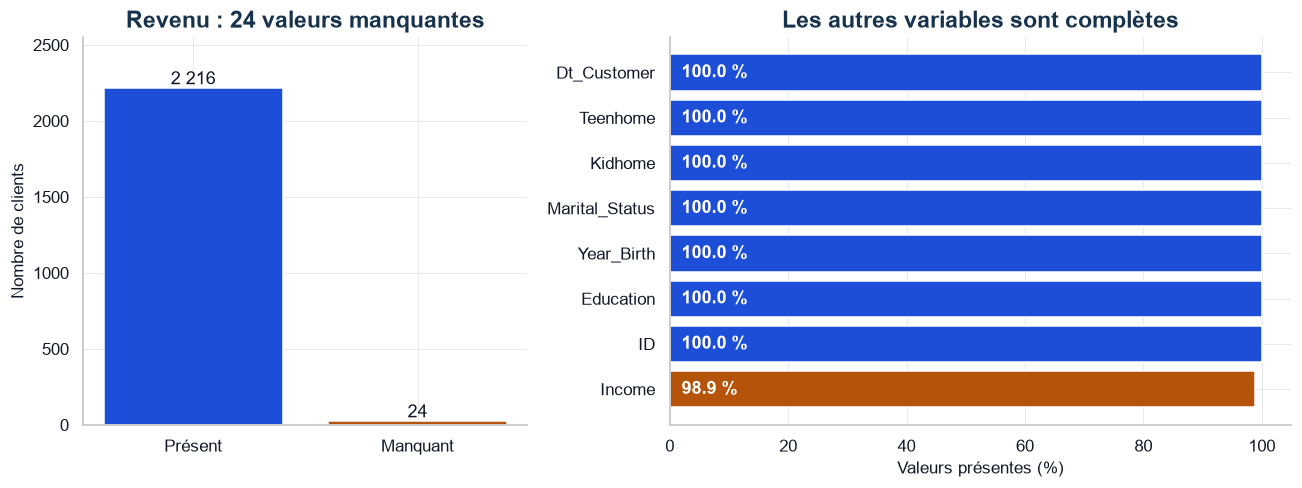

In [5]:
# Vue compacte de la qualité des données : aucune suppression n'a encore eu lieu.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})
axes[0].bar(["Présent", "Manquant"], [data["Income"].notna().sum(), data["Income"].isna().sum()], color=[pal[0], pal[2]])
for barre in axes[0].patches:
    axes[0].annotate(f"{int(barre.get_height()):,}".replace(",", " "),
                     (barre.get_x() + barre.get_width()/2, barre.get_height()), ha="center", va="bottom")
axes[0].set_title("Revenu : 24 valeurs manquantes")
axes[0].set_ylabel("Nombre de clients")
axes[0].set_ylim(0, len(data)*1.14)
completude = data.notna().mean().mul(100).sort_values().head(8)
axes[1].barh(completude.index, completude, color=[pal[2]] + [pal[0]]*7)
axes[1].set_xlim(0, 105)
axes[1].set_xlabel("Valeurs présentes (%)")
axes[1].set_title("Les autres variables sont complètes")
for i, valeur in enumerate(completude):
    axes[1].text(2, i, f"{valeur:.1f} %", color="white", va="center", fontweight="bold")
fig.tight_layout()
plt.show()

**Décision de nettoyage.** Seule `Income` comporte des valeurs manquantes : **24 clients**, soit **1,1 %** du fichier. Ces lignes sont écartées dans cette version. Une proportion faible ne garantit pas l’absence de biais ; une comparaison avec une imputation reste à mener.

`Dt_Customer` sera convertie en date. Les deux variables catégorielles conservées seront encodées avant l’ACP.

In [6]:
# Suppression des lignes sans revenu renseigné
data = data.dropna()
print("Nombre de lignes après suppression des valeurs manquantes :", len(data))

Nombre de lignes après suppression des valeurs manquantes : 2216


**Ancienneté relative du client.** `Customer_For` est la différence entre la date d’inscription la plus récente du fichier et la date d’inscription du client. Elle ne correspond pas à une ancienneté calculée à la date d’aujourd’hui.

In [7]:
# Conversion en datetime (format jour-mois-année)
data["Dt_Customer"] = pd.to_datetime(data["Dt_Customer"], dayfirst=True)

print("📅 Date d'enregistrement la plus récente :", data["Dt_Customer"].max().date())
print("📅 Date d'enregistrement la plus ancienne :", data["Dt_Customer"].min().date())

📅 Date d'enregistrement la plus récente : 2014-06-29
📅 Date d'enregistrement la plus ancienne : 2012-07-30


In [8]:
# Création de la variable "Customer_For" : ancienneté du client en jours,
# mesurée par rapport à la date d'enregistrement la plus récente
data["Customer_For"] = (data["Dt_Customer"].max() - data["Dt_Customer"]).dt.days

**Variables catégorielles.** Examiner les effectifs permet de documenter les regroupements de modalités.

In [9]:
for variable in ["Marital_Status", "Education"]:
    print(variable)
    display(tableau(data[variable].value_counts().rename("Effectif").to_frame(), precision=0))

Marital_Status


,Effectif
Marital_Status,
Married,857
Together,573
Single,471
Divorced,232
Widow,76
Alone,3
Absurd,2
YOLO,2


Education


,Effectif
Education,
Graduation,1116
PhD,481
Master,365
2n Cycle,200
Basic,54


**Sept variables dérivées** : `Customer_For`, `Age` (en 2014), `Spent` (somme des six catégories de dépenses), `Living_With`, `Children`, `Family_Size` et `Is_Parent`.

L’éducation est regroupée en trois catégories. Les identifiants, dates sources, constantes et variables remplacées sont retirés. Plusieurs variables dérivées restent liées aux variables sources : cette redondance sera discutée dans les limites.

In [10]:
# 🛠️ Ingénierie des variables

# Âge du client en 2014, fin de la période d'observation
ANNEE_REFERENCE = 2014
data["Age"] = ANNEE_REFERENCE - data["Year_Birth"]

# Dépense totale du client sur toutes les catégories de produits
data["Spent"] = (
    data["MntWines"]
    + data["MntFruits"]
    + data["MntMeatProducts"]
    + data["MntFishProducts"]
    + data["MntSweetProducts"]
    + data["MntGoldProds"]
)

# Situation de cohabitation dérivée du statut matrimonial
data["Living_With"] = data["Marital_Status"].replace({
    "Married": "Partner",
    "Together": "Partner",
    "Absurd": "Alone",
    "Widow": "Alone",
    "YOLO": "Alone",
    "Divorced": "Alone",
    "Single": "Alone",
})

# Nombre total d'enfants dans le foyer (enfants + adolescents)
data["Children"] = data["Kidhome"] + data["Teenhome"]

# Taille du foyer (adultes + enfants)
data["Family_Size"] = data["Living_With"].map({"Alone": 1, "Partner": 2}) + data["Children"]

# Statut parental (1 = parent, 0 = non parent)
data["Is_Parent"] = np.where(data["Children"] > 0, 1, 0)

# Regroupement des niveaux d'éducation en 3 catégories
data["Education"] = data["Education"].replace({
    "Basic": "Undergraduate",
    "2n Cycle": "Undergraduate",
    "Graduation": "Graduate",
    "Master": "Postgraduate",
    "PhD": "Postgraduate",
})

# Renommage des colonnes de dépenses pour plus de clarté
data = data.rename(columns={
    "MntWines": "Wines",
    "MntFruits": "Fruits",
    "MntMeatProducts": "Meat",
    "MntFishProducts": "Fish",
    "MntSweetProducts": "Sweets",
    "MntGoldProds": "Gold",
})

# Suppression des variables devenues redondantes ou inutiles
# (Z_CostContact et Z_Revenue sont constantes)
to_drop = ["Marital_Status", "Dt_Customer", "Z_CostContact", "Z_Revenue", "Year_Birth", "ID"]
data = data.drop(to_drop, axis=1)

**Statistiques après création des variables.** Les maxima permettent notamment de repérer des âges et revenus atypiques.

In [11]:
display(tableau(data.describe().T))

,count,mean,std,min,25%,50%,75%,max
Income,2216.00,52247.25,25173.08,1730.00,35303.00,51381.50,68522.00,666666.00
Kidhome,2216.00,0.44,0.54,0.00,0.00,0.00,1.00,2.00
Teenhome,2216.00,0.51,0.54,0.00,0.00,0.00,1.00,2.00
Recency,2216.00,49.01,28.95,0.00,24.00,49.00,74.00,99.00
Wines,2216.00,305.09,337.33,0.00,24.00,174.50,505.00,1493.00
Fruits,2216.00,26.36,39.79,0.00,2.00,8.00,33.00,199.00
Meat,2216.00,167.00,224.28,0.00,16.00,68.00,232.25,1725.00
Fish,2216.00,37.64,54.75,0.00,3.00,12.00,50.00,259.00
Sweets,2216.00,27.03,41.07,0.00,1.00,8.00,33.00,262.00
Gold,2216.00,43.97,51.82,0.00,9.00,24.50,56.00,321.00


Le revenu maximal est de **666 666** et l’âge maximal de **121 ans**. Ces observations justifient un examen de la qualité des saisies. La sélection ci-dessous montre aussi les relations entre revenu, dépenses, âge et ancienneté.

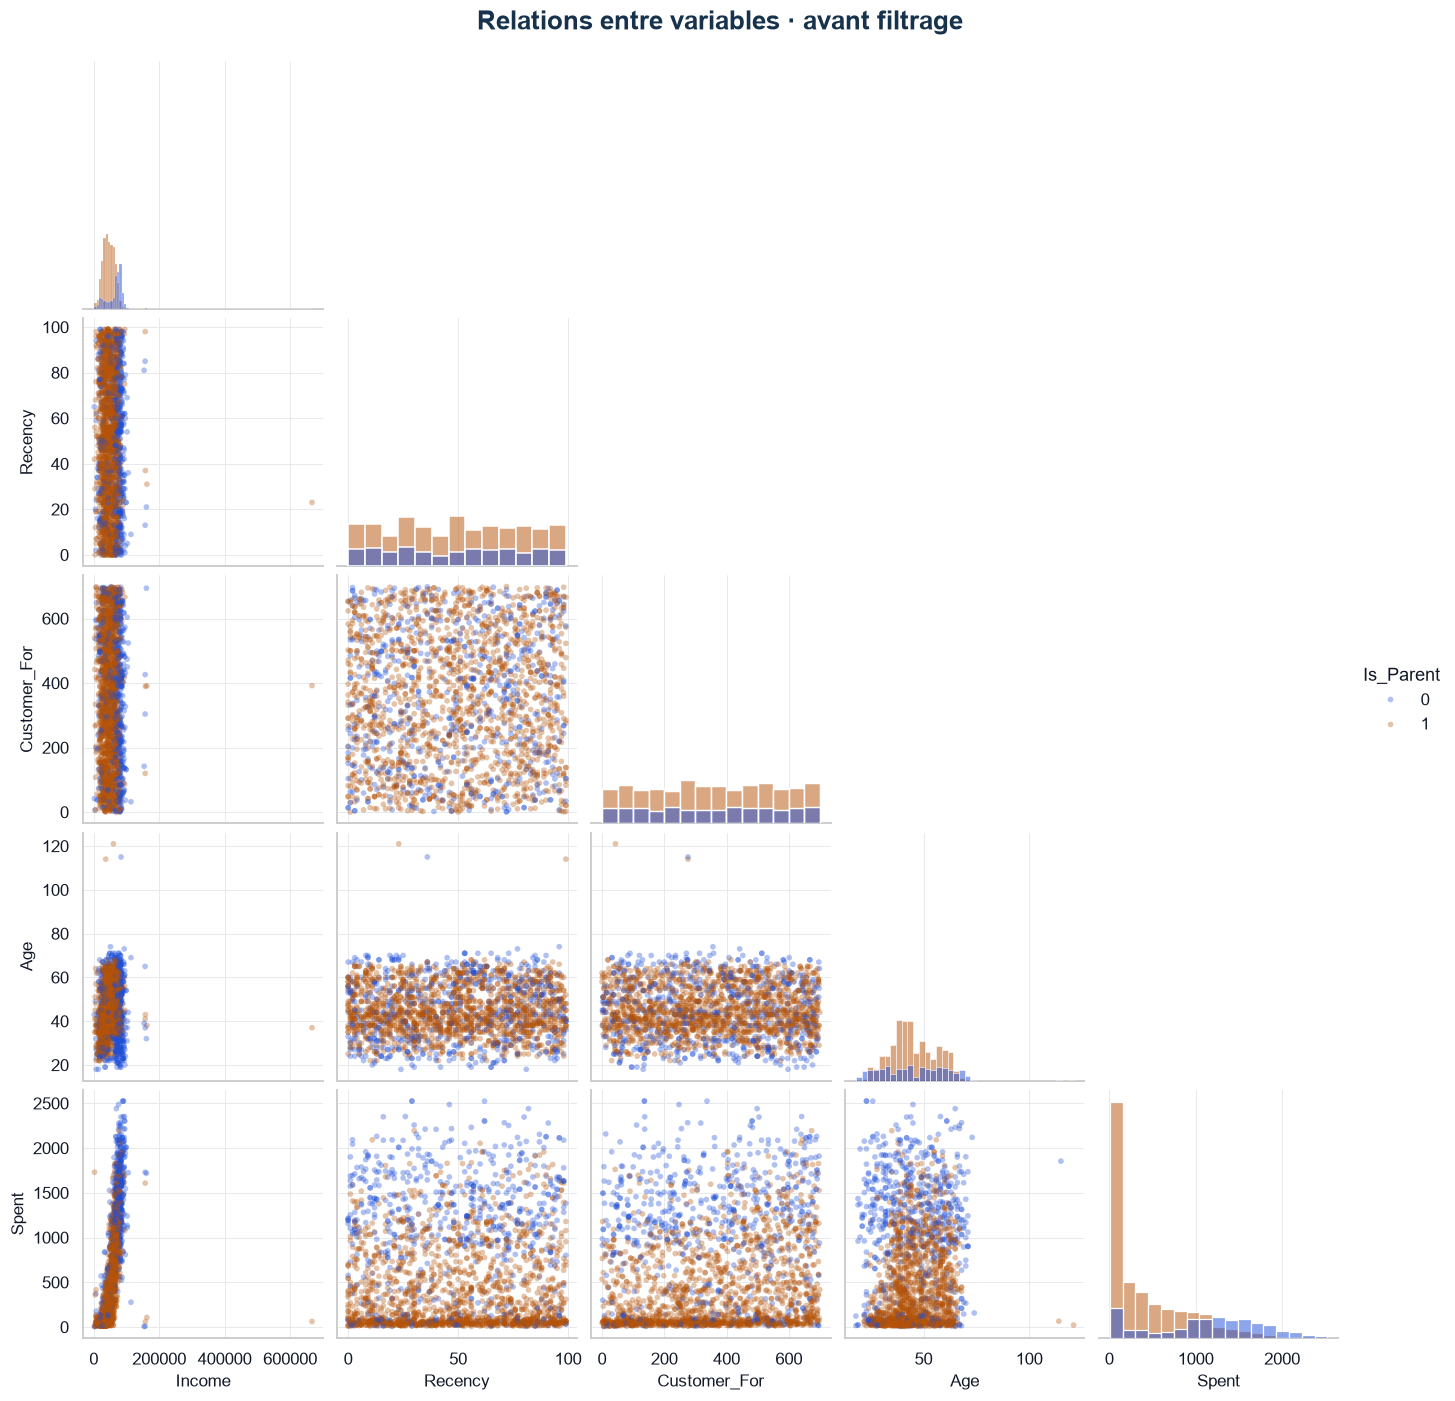

In [12]:
# Vue exploratoire avant le retrait des valeurs atypiques.
To_Plot = ["Income", "Recency", "Customer_For", "Age", "Spent", "Is_Parent"]
g = sns.pairplot(data[To_Plot], hue="Is_Parent", palette=[pal[0], pal[2]],
                 corner=True, diag_kind="hist", plot_kws={"alpha": 0.35, "s": 14, "edgecolor": "none"})
g.figure.suptitle("Relations entre variables · avant filtrage", fontsize=17, color=ENCRE, fontweight="bold", y=1.02)
plt.show()

**Filtrage documenté.** Les clients d’au moins 90 ans et les revenus d’au moins 600 000 sont retirés : **4 lignes**, après les 24 revenus manquants. Ces seuils sont des choix de nettoyage, dont la sensibilité n’est pas testée ici.

In [13]:
# Suppression des valeurs aberrantes à l'aide de seuils sur l'âge et le revenu

# Clients de 90 ans ou plus (années de naissance invraisemblables)
data = data[data["Age"] < 90]

# Revenu supérieur à 600 000
data = data[data["Income"] < 600000]

print("Nombre d'observations après suppression des valeurs aberrantes :", len(data))

Nombre d'observations après suppression des valeurs aberrantes : 2212


**Dépendances entre variables.** La carte ci-dessous concerne les variables numériques, avant l’encodage des catégories.

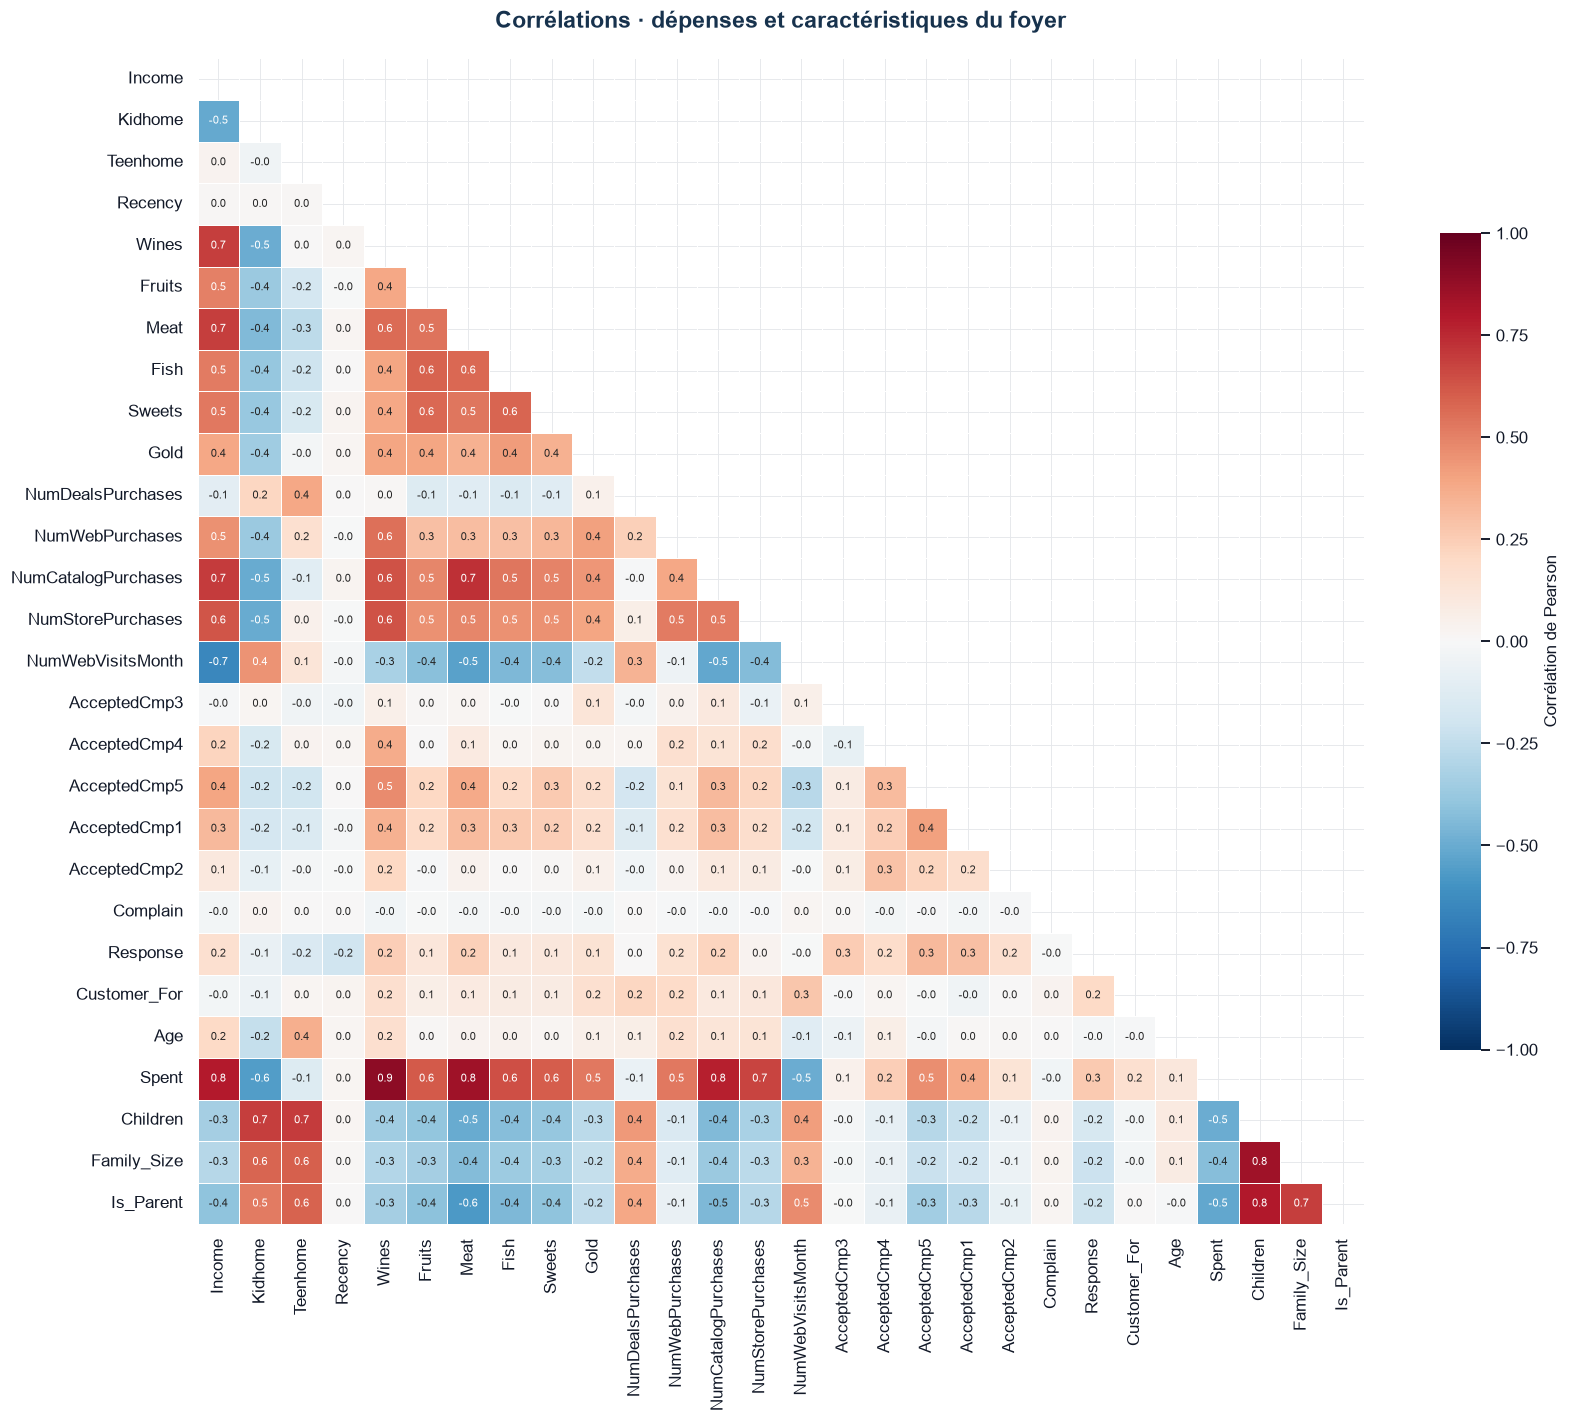

In [14]:
corrmat = data.corr(numeric_only=True)
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(corrmat, mask=np.triu(np.ones_like(corrmat, dtype=bool)), annot=True, fmt=".1f",
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            annot_kws={"fontsize": 7}, cbar_kws={"shrink": 0.7, "label": "Corrélation de Pearson"}, ax=ax)
ax.set_title("Corrélations · dépenses et caractéristiques du foyer", pad=20)
plt.tight_layout()
plt.show()

**Lecture.** Les dépenses par produit sont corrélées entre elles et avec leur somme `Spent`. Le revenu est associé aux dépenses ; les caractéristiques du foyer sont également liées entre elles. Ces associations décrivent le fichier et ne démontrent pas de causalité.

L’ACP réduit la dimension de cette représentation. Elle n’annule pas le poids supplémentaire donné à un thème représenté par plusieurs variables redondantes.

<a id="4"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">04 · Prétraitement et choix de représentation</h2>

Les catégories sont encodées, puis les variables retenues sont standardisées.

**Limite conservée.** `LabelEncoder` code l’éducation par ordre alphabétique : Graduate = 0, Postgraduate = 1, Undergraduate = 2. Ces distances ne reflètent pas une progression scolaire. Un encodage adapté est une piste d’amélioration du modèle.

In [15]:
# Liste des variables catégorielles
object_cols = [col for col in data.columns if not pd.api.types.is_numeric_dtype(data[col])]

print("Variables catégorielles :", object_cols)

Variables catégorielles : ['Education', 'Living_With']


In [16]:
# Encodage des variables catégorielles avec LabelEncoder
LE = LabelEncoder()
for col in object_cols:
    data[col] = LE.fit_transform(data[col])

print("✅ Toutes les variables sont désormais numériques.")

✅ Toutes les variables sont désormais numériques.


**Séparation des rôles.** `AcceptedCmp1` à `AcceptedCmp5`, `Response` et `Complain` sont exclus du clustering et servent au profilage après construction des groupes.

`NumDealsPurchases` et les canaux d’achat restent inclus. Leurs différences entre clusters ne constituent donc pas une validation indépendante. La standardisation donne une échelle comparable aux variables ; elle ne corrige pas leurs redondances.

In [17]:
# Copie du jeu de données
ds = data.copy()

# Retrait des variables liées aux campagnes marketing, plaintes et réponses
cols_del = ["AcceptedCmp3", "AcceptedCmp4", "AcceptedCmp5", "AcceptedCmp1", "AcceptedCmp2", "Complain", "Response"]
ds = ds.drop(cols_del, axis=1)

# Standardisation
scaler = StandardScaler()
scaled_ds = pd.DataFrame(scaler.fit_transform(ds), columns=ds.columns)

print("✅ Toutes les variables ont été mises à l'échelle.")

✅ Toutes les variables ont été mises à l'échelle.


In [18]:
print("Aperçu des 23 variables standardisées")
display(tableau(scaled_ds.head()))

Aperçu des 23 variables standardisées


,Education,Income,Kidhome,Teenhome,Recency,Wines,Fruits,Meat,Fish,Sweets,Gold,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,Customer_For,Age,Spent,Living_With,Children,Family_Size,Is_Parent
0,-0.89,0.29,-0.82,-0.93,0.31,0.98,1.55,1.69,2.45,1.48,0.85,0.35,1.43,2.50,-0.56,0.69,1.53,1.02,1.68,-1.35,-1.26,-1.76,-1.58
1,-0.89,-0.26,1.04,0.91,-0.38,-0.87,-0.64,-0.72,-0.65,-0.63,-0.73,-0.17,-1.13,-0.57,-1.17,-0.13,-1.19,1.27,-0.96,-1.35,1.40,0.45,0.63
2,-0.89,0.91,-0.82,-0.93,-0.80,0.36,0.57,-0.18,1.34,-0.15,-0.04,-0.69,1.43,-0.23,1.29,-0.54,-0.21,0.33,0.28,0.74,-1.26,-0.65,-1.58
3,-0.89,-1.18,1.04,-0.93,-0.80,-0.87,-0.56,-0.66,-0.50,-0.59,-0.75,-0.17,-0.76,-0.91,-0.56,0.28,-1.06,-1.29,-0.92,0.74,0.07,0.45,0.63
4,0.57,0.29,1.04,-0.93,1.55,-0.39,0.42,-0.22,0.15,-0.00,-0.56,1.39,0.33,0.11,0.06,-0.13,-0.95,-1.03,-0.31,0.74,0.07,0.45,0.63


La représentation standardisée est utilisée pour l’ACP. On mesure explicitement l’information conservée par les axes retenus.

<a id="5"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">05 · ACP et projection interactive</h2>

L’ACP produit des axes non corrélés résumant les variables standardisées. Les graphiques documentent le compromis entre dimension réduite et variance conservée.

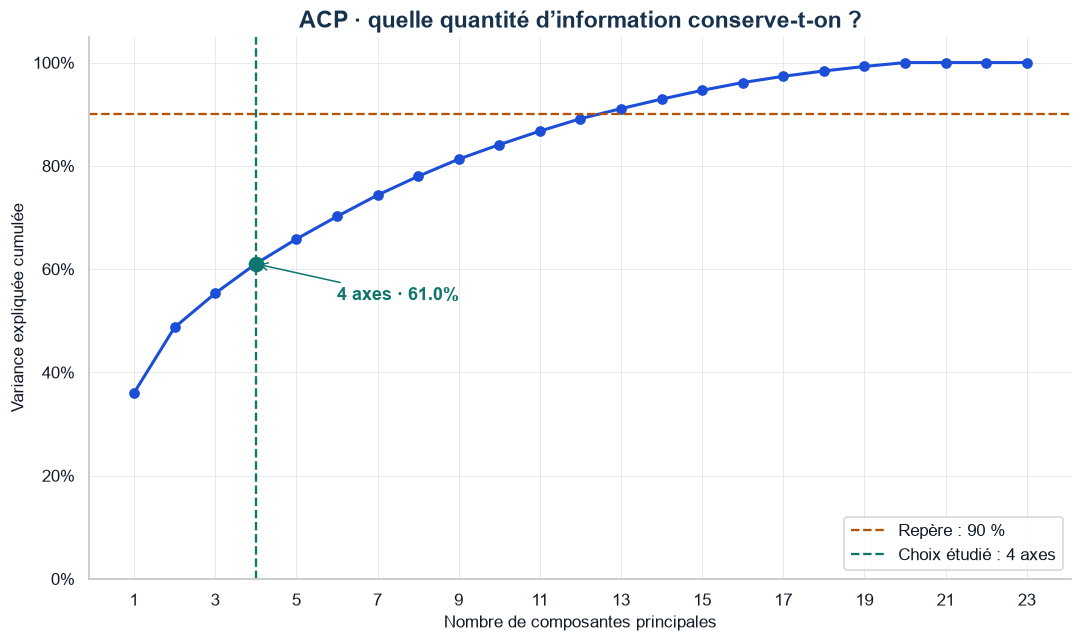

3 axes : 55.30% · 4 axes : 61.03%


In [19]:
pca_full = PCA()
pca_full.fit(scaled_ds)
cumulative_variance_full = np.cumsum(pca_full.explained_variance_ratio_)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(range(1, len(cumulative_variance_full)+1), cumulative_variance_full, marker="o", color=pal[0], linewidth=2)
ax.axhline(0.90, color=pal[2], linestyle="--", label="Repère : 90 %")
ax.axvline(4, color=pal[1], linestyle="--", label="Choix étudié : 4 axes")
ax.scatter([4], [cumulative_variance_full[3]], color=pal[1], s=85, zorder=4)
ax.annotate(f"4 axes · {cumulative_variance_full[3]:.1%}", (4, cumulative_variance_full[3]),
            xytext=(6, 0.54), arrowprops=dict(arrowstyle="->", color=pal[1]), color=pal[1], fontweight="bold")
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1))
ax.set(ylim=(0, 1.05), xlabel="Nombre de composantes principales", ylabel="Variance expliquée cumulée",
       title="ACP · quelle quantité d’information conserve-t-on ?")
ax.set_xticks(range(1, len(cumulative_variance_full)+1, 2))
ax.legend(loc="lower right", frameon=True)
fig.tight_layout()
sauvegarder("00_variance_cumulee_acp.png")
plt.show()
print(f"3 axes : {cumulative_variance_full[2]:.2%} · 4 axes : {cumulative_variance_full[3]:.2%}")

**Quatre axes conservent 61,0 % de la variance.** Le seuil de 90 % est atteint à la 13ᵉ composante. Le choix de quatre axes réduit la dimension, mais écarte environ 39 % de la variance.

Il s’agit d’un choix de représentation à comparer à d’autres nombres de composantes. La perte de variance ne prouve pas que les axes écartés ne contiennent que du bruit. Les deux vues 3D montrent seulement les trois premiers axes, soit **55,3 %** de la variance ; le clustering utilise bien **quatre axes**.

In [20]:
pca = PCA(n_components=4)
PCA_ds = pd.DataFrame(pca.fit_transform(scaled_ds), columns=["axe1", "axe2", "axe3", "axe4"])
display(tableau(PCA_ds.describe().T))

,count,mean,std,min,25%,50%,75%,max
axe1,2212.00,0.00,2.88,-5.98,-2.54,-0.78,2.39,7.45
axe2,2212.00,0.00,1.71,-4.19,-1.32,-0.17,1.23,6.17
axe3,2212.00,-0.00,1.23,-3.63,-0.85,-0.05,0.86,6.75
axe4,2212.00,0.00,1.15,-3.13,-0.76,-0.01,0.89,3.40


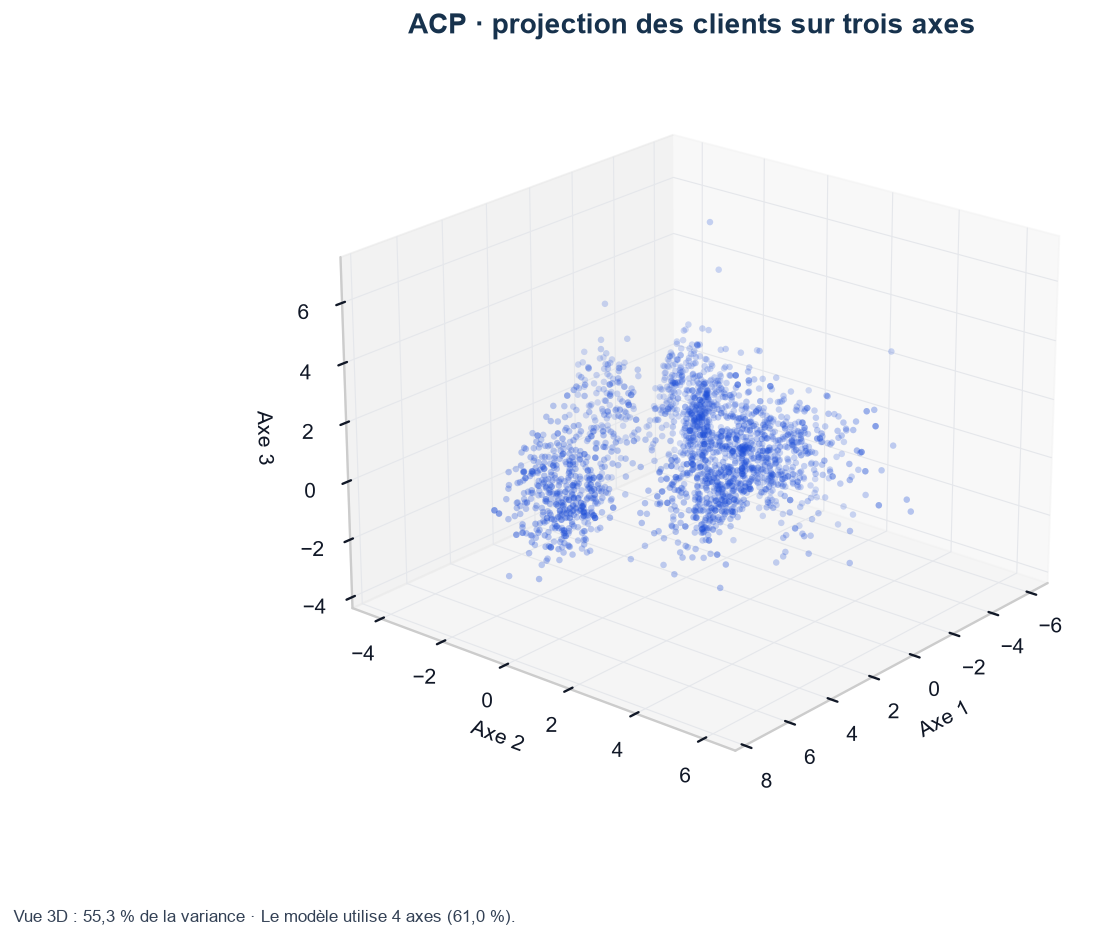

Vue interactive autonome : reports\figures_interactives\projection_acp_3d.html


In [21]:
# Projection avant la construction des groupes.
x, y, z = PCA_ds["axe1"], PCA_ds["axe2"], PCA_ds["axe3"]
fig = plt.figure(figsize=(10, 7.5))
ax = fig.add_subplot(111, projection="3d")
ax.scatter(x, y, z, c=pal[0], s=12, alpha=0.6, edgecolors="none")
ax.set(xlabel="Axe 1", ylabel="Axe 2", zlabel="Axe 3", title="ACP · projection des clients sur trois axes")
ax.view_init(elev=22, azim=40)
note_figure(fig, "Vue 3D : 55,3 % de la variance · Le modèle utilise 4 axes (61,0 %).")
afficher_3d(graphique_3d(PCA_ds, "ACP · projection des clients"), fig, "projection_acp_3d.html")

***

<a id="6"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">06 · Construction des segments</h2>

Le clustering agglomératif utilise le critère de **Ward**, sur les quatre composantes principales.

Le coude KMeans est un repère exploratoire, associé à un autre algorithme. Le choix final est confronté aux indices internes du clustering agglomératif dans la section suivante.

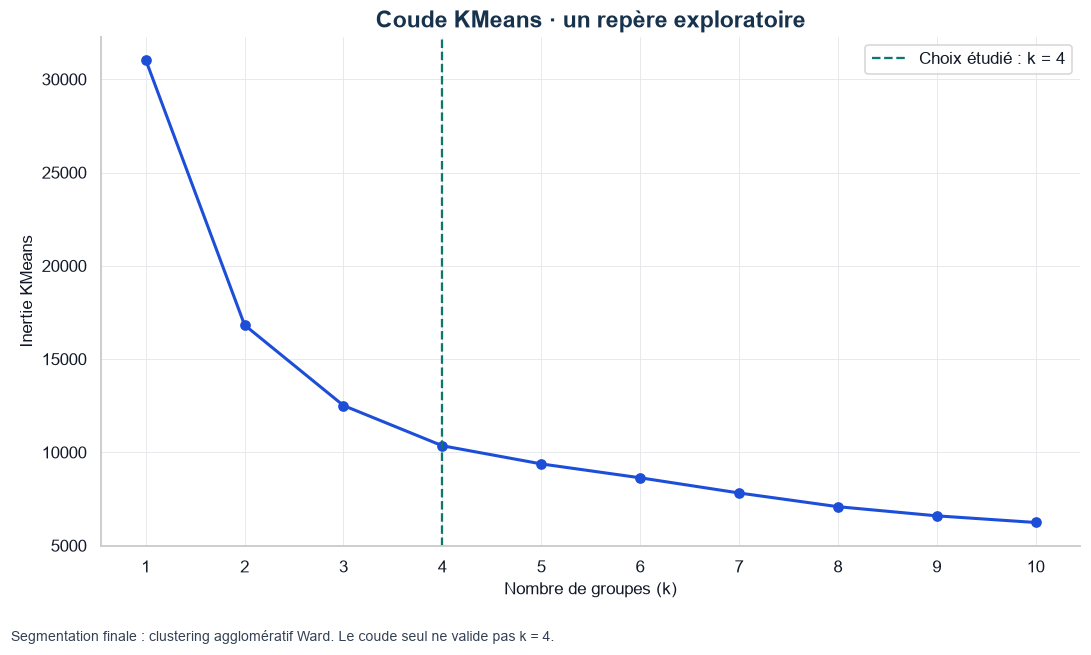

In [22]:
inertia = []
k_range = range(1, 11)
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(PCA_ds)
    inertia.append(kmeans.inertia_)
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(k_range, inertia, "o-", color=pal[0], linewidth=2)
ax.axvline(4, color=pal[1], linestyle="--", label="Choix étudié : k = 4")
ax.set(xlabel="Nombre de groupes (k)", ylabel="Inertie KMeans", title="Coude KMeans · un repère exploratoire")
ax.set_xticks(list(k_range))
ax.legend()
note_figure(fig, "Segmentation finale : clustering agglomératif Ward. Le coude seul ne valide pas k = 4.")
fig.tight_layout(rect=(0, 0.05, 1, 1))
sauvegarder("01_methode_du_coude.png")
plt.show()

Le coude est peu marqué, autour de trois à quatre groupes. **Quatre segments sont étudiés** pour décrire des profils plus détaillés. Ce choix n’est pas présenté comme optimal : il faut également regarder la séparation statistique et vérifier ultérieurement la stabilité et l’utilité des groupes.

In [23]:
# Clustering agglomératif en 4 groupes (critère de Ward)
AC = AgglomerativeClustering(n_clusters=4, linkage="ward")
yhat_AC = AC.fit_predict(PCA_ds)
PCA_ds["Clusters"] = yhat_AC

# Ajout des clusters au jeu de données d'origine
data["Clusters"] = yhat_AC

**Explorer les groupes.** Faites tourner le nuage, zoomez et survolez les clients. La légende permet de masquer ou d’isoler un cluster. L’aperçu statique conserve les couleurs et les axes de la vue interactive.

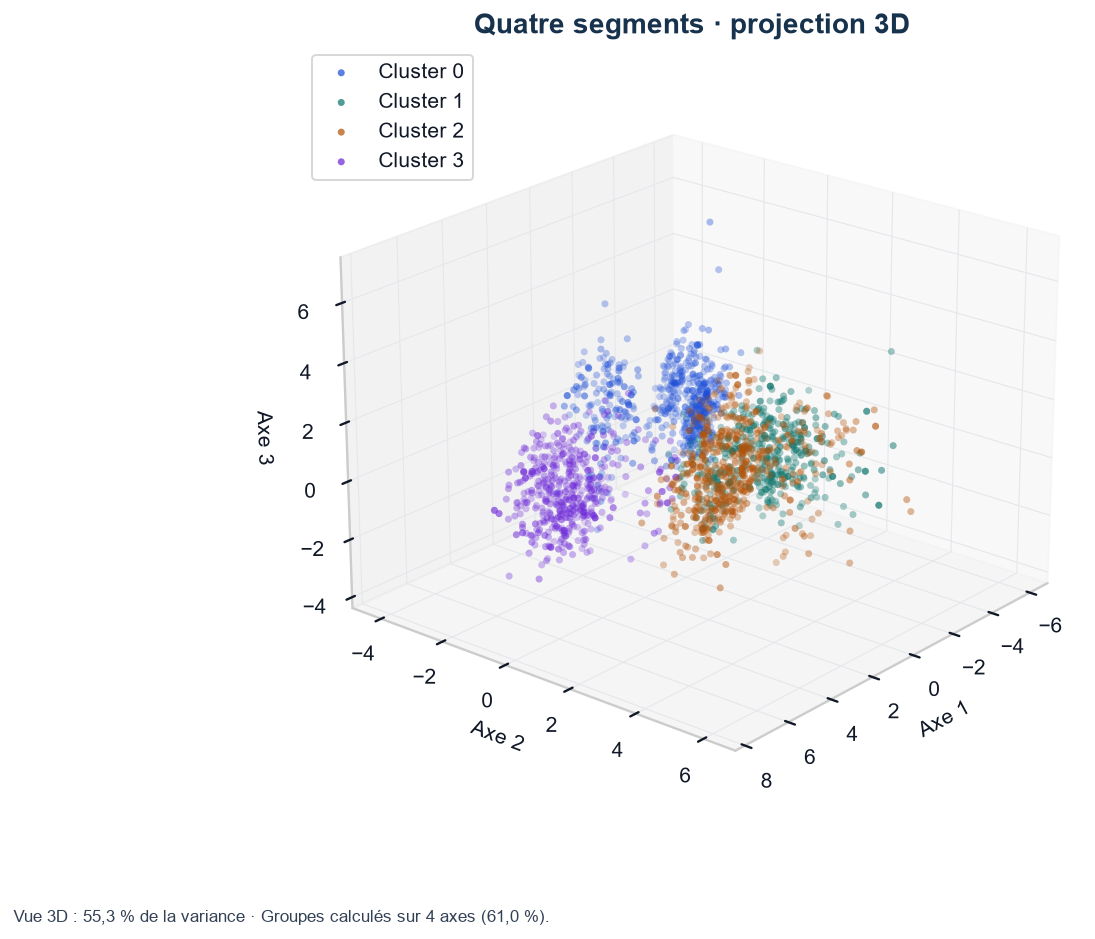

Vue interactive autonome : reports\figures_interactives\clusters_3d.html


In [24]:
fig = plt.figure(figsize=(10, 7.5))
ax = fig.add_subplot(111, projection="3d")
for groupe in range(4):
    masque = PCA_ds["Clusters"].eq(groupe)
    ax.scatter(x[masque], y[masque], z[masque], s=14, color=pal[groupe], alpha=0.72,
               edgecolors="none", label=f"Cluster {groupe}")
ax.set(xlabel="Axe 1", ylabel="Axe 2", zlabel="Axe 3", title="Quatre segments · projection 3D")
ax.view_init(elev=22, azim=40)
ax.legend(loc="upper left", frameon=True)
note_figure(fig, "Vue 3D : 55,3 % de la variance · Groupes calculés sur 4 axes (61,0 %).")
sauvegarder("02_clusters_3d.png")
afficher_3d(graphique_3d(PCA_ds, "Quatre segments · explorer les profils", groupes=True), fig, "clusters_3d.html")

La projection comporte des zones de recouvrement et dépend de l’angle de vue. Elle aide à explorer les groupes ; les indices calculés sur les quatre axes apportent une mesure complémentaire de leur séparation.

<a id="7"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">07 · Évaluation et comportements d’achat</h2>

La silhouette est meilleure quand elle augmente ; Davies-Bouldin est meilleur quand il diminue. Ces mesures internes évaluent la géométrie des groupes, sans démontrer leur rentabilité commerciale.

In [25]:
# Indices de qualité de la segmentation retenue
X_pca = PCA_ds.drop(columns="Clusters")
print(f"Coefficient de silhouette (k = 4) : {silhouette_score(X_pca, yhat_AC):.3f}")
print(f"Indice de Davies-Bouldin (k = 4)  : {davies_bouldin_score(X_pca, yhat_AC):.3f}")

# Comparaison avec d'autres nombres de clusters
scores = []
for k in range(2, 9):
    labels_k = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X_pca)
    scores.append({
        "k": k,
        "Silhouette": silhouette_score(X_pca, labels_k),
        "Davies-Bouldin": davies_bouldin_score(X_pca, labels_k),
    })
display(tableau(pd.DataFrame(scores).set_index("k"), precision=3))

Coefficient de silhouette (k = 4) : 0.304
Indice de Davies-Bouldin (k = 4)  : 1.188


,Silhouette,Davies-Bouldin
k,,
2,0.390,0.885
3,0.336,1.141
4,0.304,1.188
5,0.276,1.116
6,0.240,1.254
7,0.256,1.284
8,0.266,1.309


**Séparation modérée.** Pour quatre groupes, silhouette = **0,304** et Davies-Bouldin = **1,188**. Deux groupes obtiennent de meilleurs indices (0,390 et 0,885), tout comme trois groupes (0,336 et 1,141).

Le découpage en quatre segments offre davantage de détail descriptif. Son avantage commercial n’est pas démontré par ces indices et doit être validé séparément.

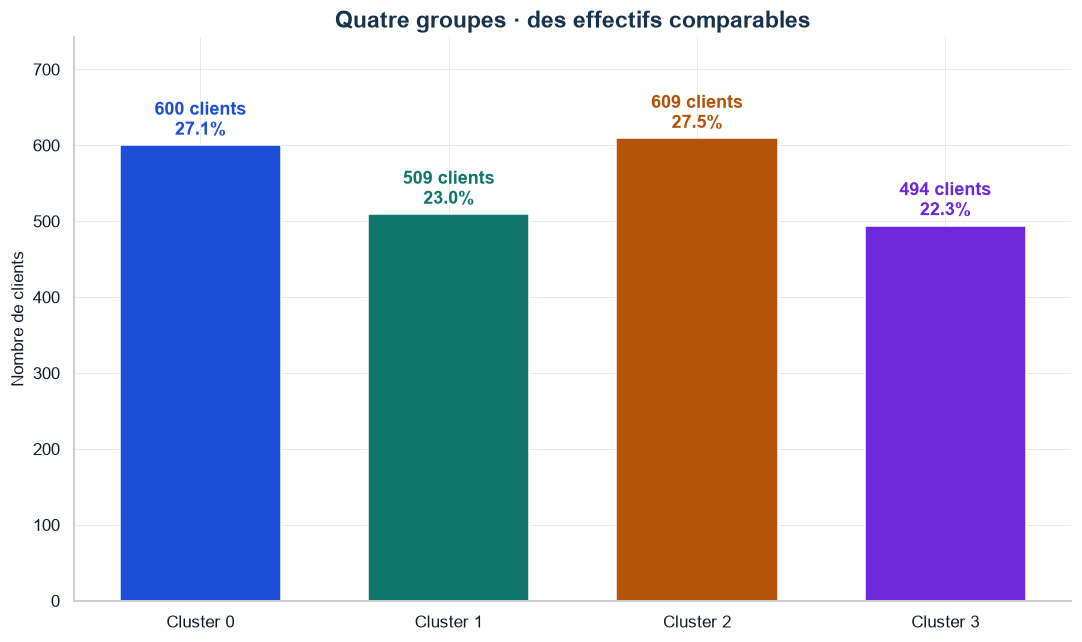

In [26]:
effectifs = data["Clusters"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(10, 6))
ax.bar([f"Cluster {i}" for i in effectifs.index], effectifs, color=pal, width=0.65)
for i, n in enumerate(effectifs):
    ax.text(i, n+14, f"{n} clients\n{n/len(data):.1%}", ha="center", fontweight="bold", color=pal[i])
ax.set(ylim=(0, effectifs.max()*1.22), ylabel="Nombre de clients", title="Quatre groupes · des effectifs comparables")
fig.tight_layout()
sauvegarder("03_repartition_clusters.png")
plt.show()

Les groupes rassemblent **600, 509, 609 et 494 clients**. Aucun n’est très petit dans cet échantillon. Leur taille ne suffit pas à démontrer leur accessibilité ni leur pertinence pour une action commerciale.

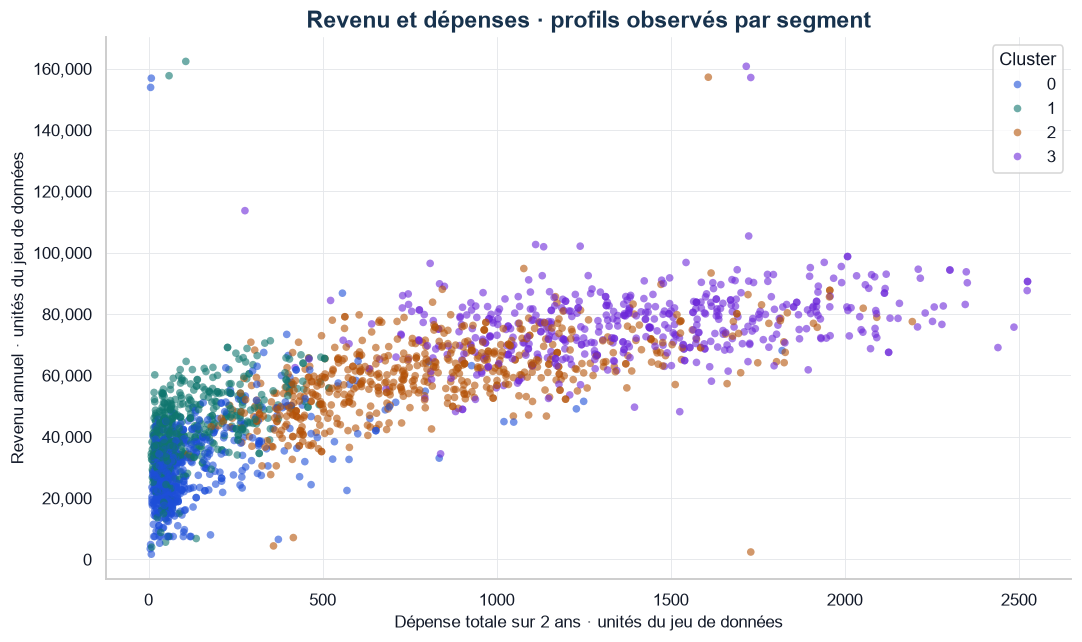

In [27]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=data, x="Spent", y="Income", hue="Clusters", palette=pal, s=25, alpha=0.6, linewidth=0, ax=ax)
ax.set(title="Revenu et dépenses · profils observés par segment",
       xlabel="Dépense totale sur 2 ans · unités du jeu de données",
       ylabel="Revenu annuel · unités du jeu de données")
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(title="Cluster", frameon=True)
fig.tight_layout()
sauvegarder("04_revenu_vs_depenses.png")
plt.show()

Les clusters 0 et 1 ont de faibles dépenses moyennes ; les clusters 2 et 3 présentent des dépenses plus élevées. Le revenu et les dépenses ont participé à la construction des groupes : cette figure décrit leur composition, sans constituer une validation externe.

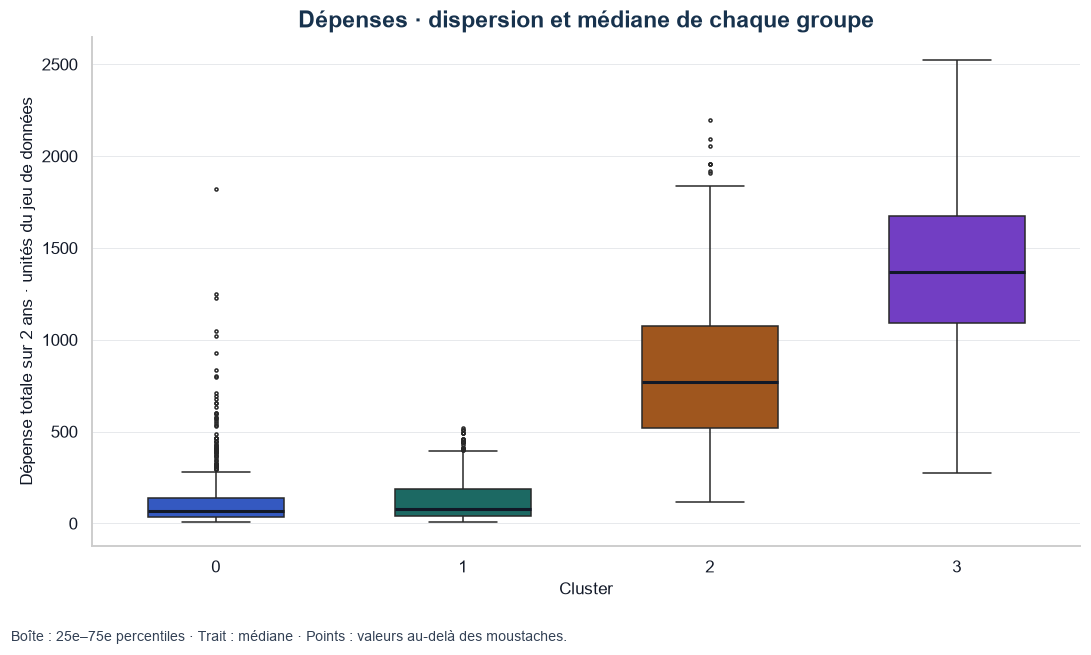

In [28]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=data, x="Clusters", y="Spent", hue="Clusters", palette=pal, legend=False,
            width=0.55, fliersize=2, medianprops={"color": "#111827", "linewidth": 2}, ax=ax)
ax.set(title="Dépenses · dispersion et médiane de chaque groupe", xlabel="Cluster",
       ylabel="Dépense totale sur 2 ans · unités du jeu de données")
note_figure(fig, "Boîte : 25e–75e percentiles · Trait : médiane · Points : valeurs au-delà des moustaches.")
fig.tight_layout(rect=(0, 0.05, 1, 1))
sauvegarder("05_distribution_depenses.png")
plt.show()

Les boîtes montrent les écarts de médiane et la dispersion interne. Les moyennes seules ne résument pas toute la diversité des clients à l’intérieur d’un segment.

**Réponses observées aux campagnes.** Les variables d’acceptation ont été exclues de la construction des groupes. Leur comparaison fournit un descriptif complémentaire.

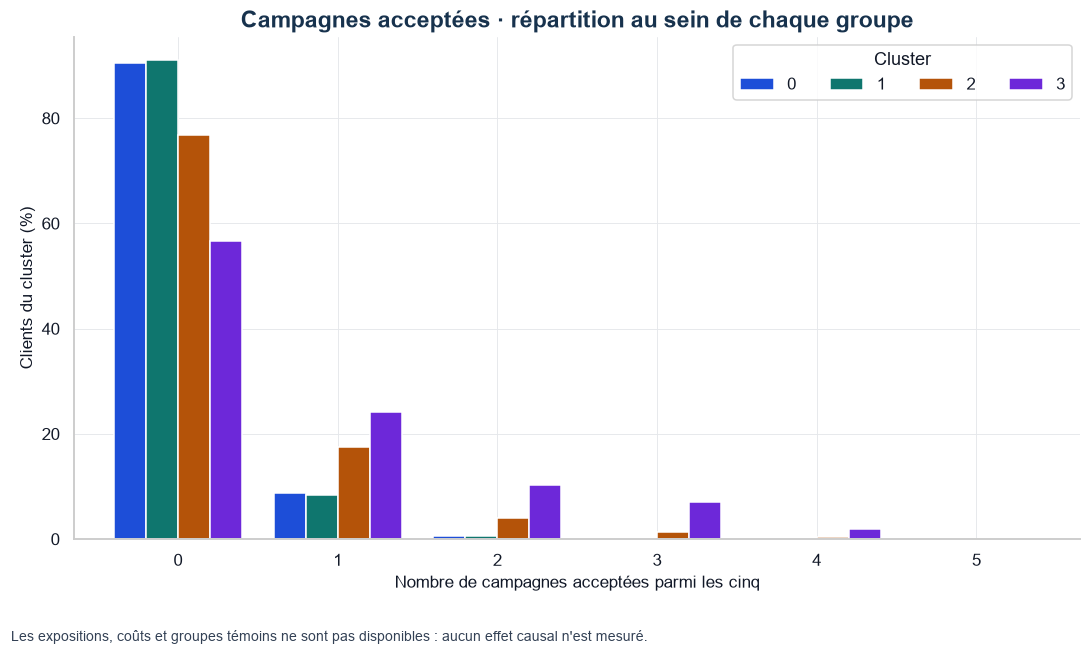

Aucune des cinq campagnes acceptée : 79.3%


,Total_Promos,Response
Clusters,,
0,0.10,0.12
1,0.10,0.06
2,0.31,0.12
3,0.73,0.31


In [29]:
# Nombre total de campagnes acceptées par client
data["Total_Promos"] = (
    data["AcceptedCmp1"] + data["AcceptedCmp2"] + data["AcceptedCmp3"] + data["AcceptedCmp4"] + data["AcceptedCmp5"]
)


# Pourcentages à l'intérieur de chaque cluster, afin de comparer des groupes de tailles différentes.
acceptations = pd.crosstab(data["Total_Promos"], data["Clusters"], normalize="columns").mul(100)
acceptations = acceptations.reindex(range(6), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 6))
acceptations.plot.bar(ax=ax, color=pal, width=0.8)
ax.set(title="Campagnes acceptées · répartition au sein de chaque groupe",
       xlabel="Nombre de campagnes acceptées parmi les cinq", ylabel="Clients du cluster (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Cluster", ncol=4, loc="upper right")
note_figure(fig, "Les expositions, coûts et groupes témoins ne sont pas disponibles : aucun effet causal n'est mesuré.")
fig.tight_layout(rect=(0, 0.06, 1, 1))
sauvegarder("06_promos_par_cluster.png")
plt.show()
print(f"Aucune des cinq campagnes acceptée : {(data['Total_Promos'] == 0).mean():.1%}")
display(tableau(data.groupby("Clusters")[["Total_Promos", "Response"]].mean()))

**79,3 % des clients** n’ont accepté aucune des cinq campagnes. Le cluster 3 a le nombre moyen d’acceptations le plus élevé et la plus forte proportion de réponses positives à la dernière campagne (**30,6 %**).

On ne connaît pas les expositions individuelles, les coûts ni un groupe témoin. Ces écarts ne permettent pas de conclure que les campagnes étaient mal ciblées ou qu’une nouvelle campagne sera efficace.

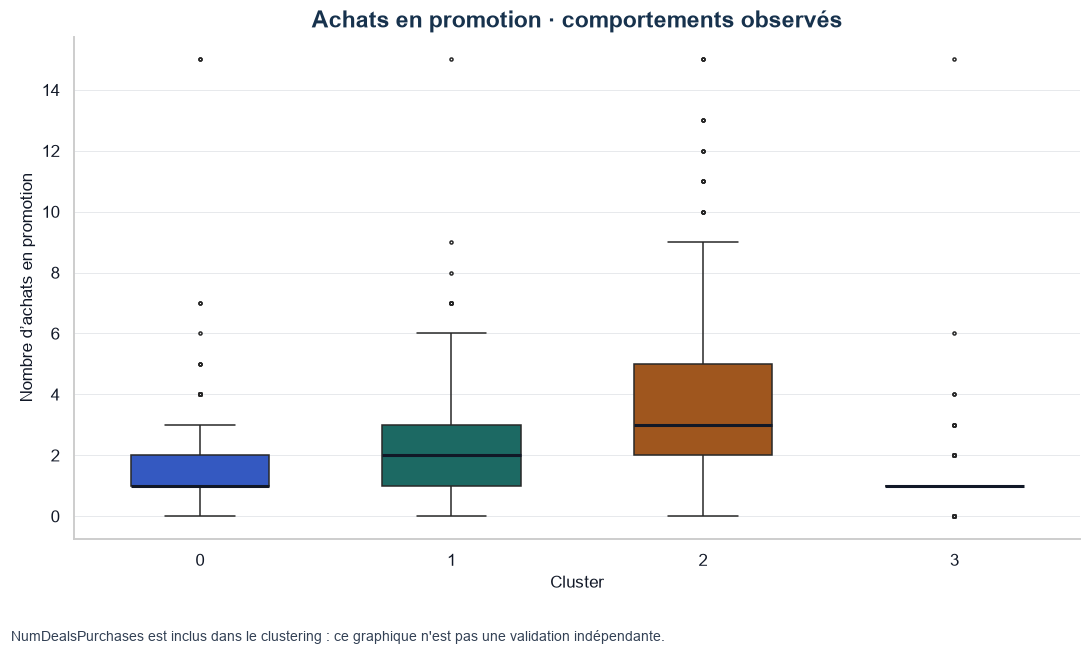

In [30]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=data, x="Clusters", y="NumDealsPurchases", hue="Clusters", palette=pal, legend=False,
            width=0.55, fliersize=2, medianprops={"color": "#111827", "linewidth": 2}, ax=ax)
ax.set(title="Achats en promotion · comportements observés", xlabel="Cluster", ylabel="Nombre d’achats en promotion")
ax.yaxis.set_major_locator(mticker.MaxNLocator(integer=True))
note_figure(fig, "NumDealsPurchases est inclus dans le clustering : ce graphique n'est pas une validation indépendante.")
fig.tight_layout(rect=(0, 0.06, 1, 1))
sauvegarder("07_deals_par_cluster.png")
plt.show()

Le cluster 2 présente davantage d’achats en promotion (**3,7 en moyenne**) et le cluster 3 moins (**1,1**). Cette variable étant incluse dans le clustering, ces différences font partie de la description des groupes.

Elles ne mesurent ni la sensibilité causale au prix ni les achats qui auraient eu lieu sans remise. Une comparaison contrôlée d’offres avec et sans remise permettrait de tester ces hypothèses.

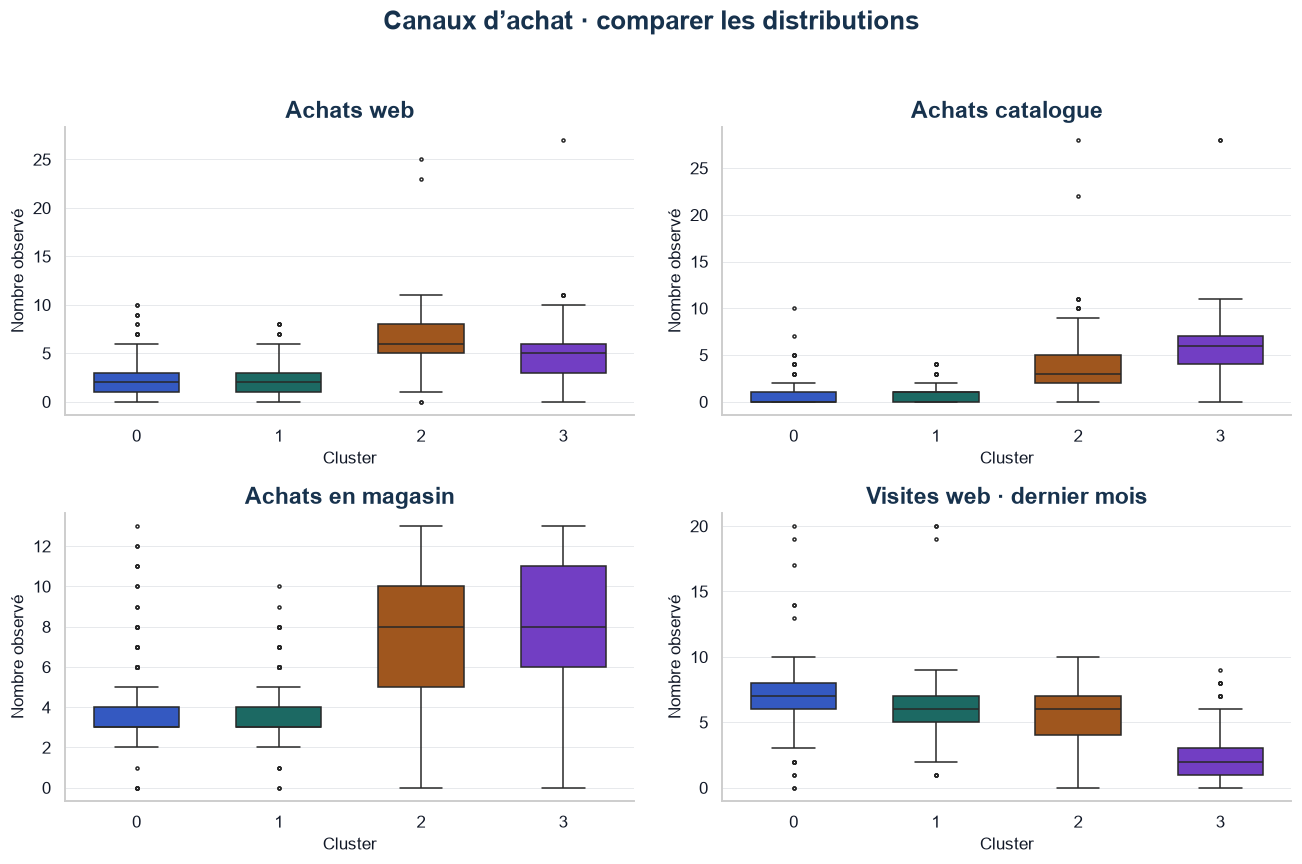

,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth
Clusters,,,,
0,2.3,0.7,3.4,6.7
1,2.3,0.7,3.6,5.9
2,6.5,3.6,7.9,5.6
3,5.0,6.0,8.3,2.6


In [31]:
lieux_achat = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases", "NumWebVisitsMonth"]
libelles = ["Achats web", "Achats catalogue", "Achats en magasin", "Visites web · dernier mois"]
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, variable, libelle in zip(axes.flat, lieux_achat, libelles):
    sns.boxplot(data=data, x="Clusters", y=variable, hue="Clusters", palette=pal, legend=False,
                width=0.6, fliersize=2, ax=ax)
    ax.set(title=libelle, xlabel="Cluster", ylabel="Nombre observé")
fig.suptitle("Canaux d’achat · comparer les distributions", color=ENCRE, fontweight="bold", fontsize=17)
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()
display(tableau(data.groupby("Clusters")[lieux_achat].mean(), precision=1))

Le cluster 3 effectue davantage d’achats par catalogue et en magasin ; le cluster 2 est actif sur le web. Les clusters 0 et 1 enregistrent davantage de visites web que d’achats web.

Les visites portent sur le dernier mois, tandis que les achats n’ont pas la même fenêtre explicitée dans le fichier. Leurs rapports ne sont donc pas interprétés comme des taux de conversion. Les canaux d’achat ont également participé au clustering.

<a id="8"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">08 · Profils des clients</h2>

Les moyennes et proportions ci-dessous décrivent les segments dans l’échantillon. Les noms des profils sont des résumés descriptifs ; ils ne prédisent pas le comportement futur de chaque client.

In [32]:
# Tableau de synthèse des profils (moyennes par cluster)
profil = data.groupby("Clusters").agg(
    Effectif=("Income", "size"),
    Revenu=("Income", "mean"),
    Depense_totale=("Spent", "mean"),
    Age=("Age", "mean"),
    Part_parents=("Is_Parent", "mean"),
    Enfants=("Kidhome", "mean"),
    Adolescents=("Teenhome", "mean"),
    Taille_foyer=("Family_Size", "mean"),
    Taille_foyer_max=("Family_Size", "max"),
    Achats_promo=("NumDealsPurchases", "mean"),
    Campagnes_acceptees=("Total_Promos", "mean"),
    Reponse_derniere_campagne=("Response", "mean"),
)
display(tableau(profil.T))

Clusters,0,1,2,3
Effectif,600.00,509.00,609.00,494.00
Revenu,31163.83,42641.73,60135.16,76736.10
Depense_totale,129.69,127.17,832.78,1403.98
Age,37.46,49.26,48.21,46.20
Part_parents,0.73,1.00,1.00,0.05
Enfants,0.72,0.78,0.24,0.01
Adolescents,0.01,1.02,0.94,0.05
Taille_foyer,2.35,3.48,2.89,1.62
Taille_foyer_max,3.00,5.00,5.00,2.00
Achats_promo,1.76,2.54,3.70,1.09


**Lire les distributions.** Les variables catégorielles sont représentées par des proportions, plutôt que par des densités continues. L’âge et l’ancienneté sont comparés avec des boîtes à moustaches.

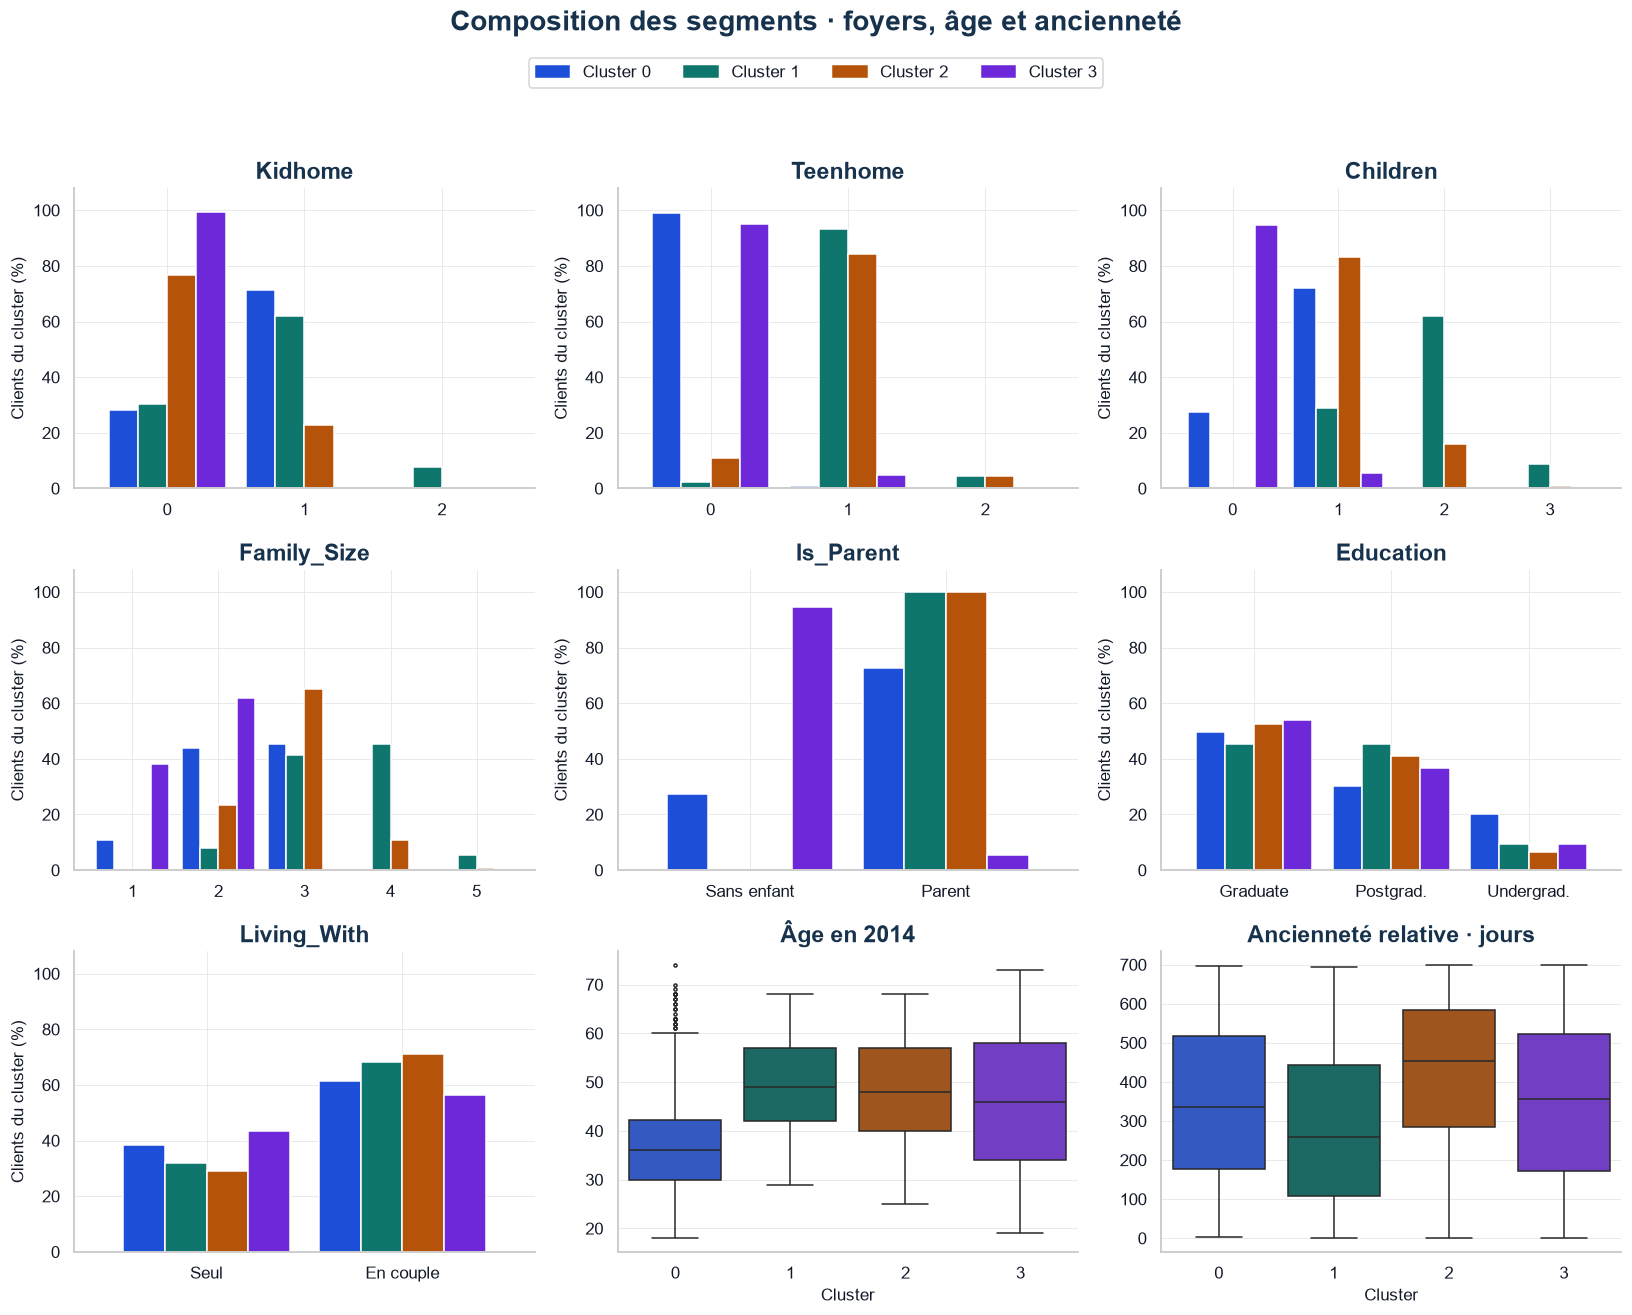

In [33]:
variables_personnelles = ["Kidhome", "Teenhome", "Children", "Family_Size", "Is_Parent", "Education", "Living_With"]
fig, axes = plt.subplots(3, 3, figsize=(15, 12))
for ax, variable in zip(axes.flat, variables_personnelles):
    parts = pd.crosstab(data[variable], data["Clusters"], normalize="columns").mul(100)
    if variable == "Education":
        parts = parts.rename(index={0: "Graduate", 1: "Postgrad.", 2: "Undergrad."})
    elif variable == "Living_With":
        parts = parts.rename(index={0: "Seul", 1: "En couple"})
    elif variable == "Is_Parent":
        parts = parts.rename(index={0: "Sans enfant", 1: "Parent"})
    parts.plot.bar(ax=ax, color=pal, legend=False, width=0.85)
    ax.set(title=variable, xlabel="", ylabel="Clients du cluster (%)", ylim=(0, 108))
    ax.tick_params(axis="x", rotation=0)
for ax, variable in zip(list(axes.flat)[7:], ["Age", "Customer_For"]):
    sns.boxplot(data=data, x="Clusters", y=variable, hue="Clusters", palette=pal, legend=False, fliersize=2, ax=ax)
    ax.set(title="Âge en 2014" if variable == "Age" else "Ancienneté relative · jours", xlabel="Cluster", ylabel="")
fig.legend(handles=[Patch(color=pal[i], label=f"Cluster {i}") for i in range(4)],
           loc="upper center", ncol=4, bbox_to_anchor=(0.5, 0.965))
fig.suptitle("Composition des segments · foyers, âge et ancienneté", color=ENCRE, fontsize=18, fontweight="bold", y=0.995)
fig.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

**Synthèse descriptive des profils**

<table style="width:100%;border-collapse:collapse;background:#F3F4F6;color:#000000;font-family:Arial,sans-serif;">
<thead>
<tr>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Segment</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Effectif</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Profil observé</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>0 · Jeunes foyers à faible revenu</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">600</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 37 ans ; revenu moyen 31 164 ; dépenses moyennes 130 ; 72,7 % de parents.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>1 · Foyers avec enfants, faibles dépenses</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">509</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 49 ans ; revenu moyen 42 642 ; dépenses moyennes 127 ; 100 % de parents.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>2 · Foyers avec enfants, dépenses intermédiaires</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">609</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 48 ans ; revenu moyen 60 135 ; dépenses moyennes 833 ; 99,8 % de parents ; achats en promotion plus nombreux.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;"><strong>3 · Foyers surtout sans enfant, fortes dépenses</strong></td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">494</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Âge moyen 46 ans ; revenu moyen 76 736 ; dépenses moyennes 1 404 ; 94,5 % sans enfant ; réponse positive à la dernière campagne : 30,6 %.</td>
</tr>
</tbody>
</table>


Les montants sont exprimés dans les unités monétaires du jeu de données.

<a id="9"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">09 · Enseignements, hypothèses et limites</h2>

**Résultats observés.** Quatre groupes décrivent des différences de revenu, de dépenses et de composition du foyer. Les campagnes exclues du modèle apportent un descriptif complémentaire. Le découpage reste modérément séparé et n’est pas une preuve de quatre populations naturellement distinctes.

**Hypothèses commerciales à tester**

<table style="width:100%;border-collapse:collapse;background:#F3F4F6;color:#000000;font-family:Arial,sans-serif;">
<thead>
<tr>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Segment</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Expérience envisageable</th>
  <th style="background:#D1D5DB;color:#000000;font-weight:700;padding:10px;">Ce qu’il faudrait mesurer</th>
</tr>
</thead>
<tbody>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">0</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Tester des parcours ou messages web adaptés.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Achats additionnels, avec des visites et achats mesurés sur la même période.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">1</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Comparer plusieurs offres pour les foyers avec enfants.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Réponse et achats supplémentaires par rapport à un groupe témoin.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">2</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Comparer une offre avec remise à une offre sans remise.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Achats additionnels et marge, avec les coûts réels de la remise.</td>
</tr>
<tr>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">3</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Tester une campagne centrée sur une sélection de produits.</td>
  <td style="background:#F3F4F6;color:#000000;padding:10px;border-bottom:1px solid #D1D5DB;">Réponse, achats additionnels et marge par rapport à un groupe témoin.</td>
</tr>
</tbody>
</table>


**Limites à garder visibles**

- **Séparation modérée** : silhouette 0,304 ; deux et trois groupes ont de meilleurs indices internes. Quatre groupes ne sont pas présentés comme l’optimum statistique.
- **Choix de représentation** : quatre axes conservent 61,0 % de la variance ; le coude KMeans n’est qu’un repère pour un modèle final Ward.
- **Redondance** : les dépenses et les variables familiales sont représentées plusieurs fois ; cela influence les distances.
- **Encodage** : l’ordre alphabétique de l’éducation n’est pas un ordre de niveau d’études. Un autre encodage doit être comparé avant de retenir une version améliorée du modèle.
- **Nettoyage** : 24 revenus manquants et 4 observations atypiques sont retirés. Le biais de sélection et la sensibilité aux seuils n’ont pas été évalués.
- **Validation indépendante** : les achats promotionnels et les canaux d’achat ont servi au clustering. Aucune stabilité par rééchantillonnage ni validation sur une nouvelle période n’a été mesurée.
- **Causalité** : l’exposition aux campagnes, les coûts, les marges et des groupes témoins manquent. Aucune économie ni hausse de ventes n’est établie.

La prochaine amélioration méthodologique serait de comparer des représentations moins redondantes et des encodages adaptés, puis de mesurer la stabilité des profils. Les hypothèses commerciales demandent ensuite des données et expériences dédiées.

<a id="10"></a>
<h2 style="color:#2563EB;font-family:Arial,sans-serif;font-weight:700;border-bottom:2px solid #DBEAFE;padding-bottom:12px;">10 · Sources et équipe</h2>

- **Données :** [Customer Personality Analysis](https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis), Akash Patel, Kaggle.
- **Démarche initiale :** [Customer Segmentation: Clustering](https://www.kaggle.com/code/karnikakapoor/customer-segmentation-clustering), Karnika Kapoor. La préparation des données et l’enchaînement ACP + clustering agglomératif s’en inspirent. L’évaluation, l’interprétation et le profilage sont présentés dans le cadre du projet collectif.
- **Lecture interactive :** les deux exports HTML autonomes sont régénérés par ce notebook. GitHub affiche une vue statique des notebooks et ne lance pas leur JavaScript.

---

**Abdoulaye KONE — Statisticien, diplômé de l’ENSEA**  
Contribution : nettoyage et création de variables, ACP, choix des segments et rédaction de l’analyse.  
[LinkedIn](https://linkedin.com/in/abdoulaye-kone) · [GitHub](https://github.com/abdoul4Kone)

**Projet collectif** : KONE Abdoulaye · N’GUESSAN Kouamé Kan Armand Loïc · SAWADOGO Wend-yam Albert · CHEFOUET CHETSONG Ghislain Joël.  
Supervision : M. LALY · ENSEA Abidjan, Data Mining, juillet 2025.